In [1]:
# First, let's check which Python interpreter is being used by this notebook
import sys
print(f"Current Python executable: {sys.executable}")

# Let's see all available environments
!conda env list

# Let's check if we're in a conda environment and which one
import os
print(f"CONDA_DEFAULT_ENV: {os.environ.get('CONDA_DEFAULT_ENV', 'Not set')}")

# Let's try to install ortools directly in the current environment
!{sys.executable} -m pip install ortools

# After installation, try importing again
try:
    from ortools.constraint_solver import routing_enums_pb2
    from ortools.constraint_solver import pywrapcp
    print("Successfully imported ortools modules")
except ImportError as e:
    print(f"Import error: {e}")
!{sys.executable} -m pip install polars

Current Python executable: C:\Users\Administrator\.conda\envs\ml_env\python.exe

# conda environments:
#
base                   C:\ProgramData\anaconda3
NER_env_1              C:\Users\Administrator\.conda\envs\NER_env_1
ml_env               * C:\Users\Administrator\.conda\envs\ml_env
ml_env — копия         C:\Users\Administrator\.conda\envs\ml_env — копия

CONDA_DEFAULT_ENV: ml_env
Successfully imported ortools modules



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from typing import Dict, List, Tuple, Optional
from collections import defaultdict, deque
from scipy import stats

RANGE = 0.9
AGENT_IDS = [318, 434]
LEARNING_RATE_ACTOR = 1e-4
LEARNING_RATE_CRITIC = 1e-3
GAMMA = 0.99
TAU = 0.005
BATCH_SIZE = 64
CLIP_GRAD = 1.0

BETA_TEMPERATURE = 2.0
ENTROPY_COEF = 0.05
BETA_MAX = 20.0
ON_POLICY_BUFFER_SIZE = 128

agent_config = {318: 'marl', 
                434: 'marl'
               }
TENDER_POLYGONS = [9353]

STATIC_BR = {
    318: 0.5,
    434: 0.5
}
STATIC_V = 1 - sum(STATIC_BR.values())
U_GLOBAL = 900 

def set_seeds(seed: int = 42):
    """Set all random seeds for reproducibility."""
    import os
    import random
    import numpy as np
    import torch
    
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

class TheoreticalBidDistribution:
    def __init__(self, br_1: float, br_2: float, U: float):
        self.br_i = max(br_1, br_2)
        self.br_j = min(br_1, br_2)
        self.U = U
        self.V = STATIC_V
        self.P_lower = (self.br_i * self.U) / (self.br_i + self.V)
    
    def get_theoretical_cdf(self, P: float, agent_type: str) -> float:
        if P < self.P_lower:
            return 0.0
        elif P >= self.U:
            return 1.0
        else:
            if agent_type == 'i':
                if P == self.U:
                    return (self.br_i-self.br_j)/(self.br_i+self.V)
                return (1.0 + self.br_j / self.V - 
                       self.br_i * self.U * (self.br_j + self.V) / 
                       (self.br_i + self.V) / self.V / P)
            else:
                return 1.0 - self.br_i * (self.U - P) / self.V / P
    
    def generate_theoretical_sample(self, n_samples: int = 1000, 
                                    agent_type: str = 'i') -> np.ndarray:
        u = np.random.uniform(0, 1, n_samples)
        
        if agent_type == 'j':
            # F_j(P) = 1 - br_i*(U - P) / (V * P)  =>  P = (br_i * U) / (V*(1 - u) + br_i)
            samples = (self.br_i * self.U) / (self.V * (1.0 - u) + self.br_i)
        else:
            # F_i(P) = A - B/P  =>  P = B / (A - u)
            # where A = 1 + br_j/V, B = [br_i * U * (br_j + V)] / [(br_i + V) * V]
            A = 1.0 + self.br_j / self.V
            B = (self.br_i * self.U * (self.br_j + self.V)) / ((self.br_i + self.V) * self.V)
            samples = B / (A - u)
        
        samples = np.clip(samples, self.P_lower, self.U)
        
        return samples
    
    def ks_test_convergence(self, empirical_samples, agent_type):
        xs = np.sort(empirical_samples)
        F_emp = np.arange(1, len(xs)+1) / len(xs)
        F_th = np.array([self.get_theoretical_cdf(x, agent_type) for x in xs])
    
        ks_statistic = np.max(np.abs(F_emp - F_th))
    
        n = len(xs)
        p_value = stats.kstwo.sf(ks_statistic, n)
    
        return {
            "ks_statistic": float(ks_statistic),
            "p_value": float(p_value),
            "converged": bool(p_value > 0.8),
            "sample_size": n
        }
        
class Courier:
    def __init__(self, id: int):
        self.id = id
        self.trust_score: float = 0.5
        self.br: float = STATIC_BR.get(id)

class ActorNetwork(nn.Module):
    def __init__(self, state_dim: int = 4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU()
        )
        
        self.alpha_head = nn.Linear(128, 1)
        self.beta_head = nn.Linear(128, 1)

    def forward(self, state):
        x = self.net(state)
        
        alpha = F.softplus(self.alpha_head(x)) + 1e-3
        alpha = torch.clamp(alpha, max=BETA_MAX)
        
        beta = F.softplus(self.beta_head(x)) + 1e-3
        beta = torch.clamp(beta, max=BETA_MAX)
        
        return alpha, beta

class CriticNetwork(nn.Module):
    def __init__(self, state_dim: int = 4):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_dim + 1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    
    def forward(self, state: torch.Tensor, action: torch.Tensor) -> torch.Tensor:
        x = torch.cat([state, action], dim=-1)
        return self.network(x)

class DCMABAgent:
    def __init__(self, agent_id: int, state_dim: int = 4):
        self.agent_id = agent_id
        
        self.actor = ActorNetwork(state_dim)
        self.actor_target = ActorNetwork(state_dim)
        self.actor_target.load_state_dict(self.actor.state_dict())
        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=LEARNING_RATE_ACTOR)
        
        self.critic = CriticNetwork(state_dim)
        self.critic_target = CriticNetwork(state_dim)
        self.critic_target.load_state_dict(self.critic.state_dict())
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=LEARNING_RATE_CRITIC)
        
        self.on_policy_buffer = deque(maxlen=ON_POLICY_BUFFER_SIZE)
        
        self.bid_history: List[float] = []
        self.reward_history: List[float] = []
        
        self.wins = 0
        self.total_games = 0
        self.win_rate = 0.0

        self.action_history_window = deque(maxlen=20)
        self.log_prob_history = deque(maxlen=20)
        
        self.current_br = 0.0
        
        self.reward_baseline = 0.0
        self.baseline_momentum = 0.9
    
    def sample_policy_bids(self, state, P_lower, U, n_samples=1000):
        self.actor.eval()
        
        with torch.no_grad():
            alpha, beta = self.actor(state)
            dist = torch.distributions.Beta(alpha, beta)
            
            samples = dist.sample((n_samples,))
            samples = samples.squeeze().cpu().numpy()
        
        bids = P_lower + samples * (U - P_lower)
        return bids

    def estimate_opponent_cdf(self, bid, opponent_bid_history):
        if len(opponent_bid_history) < 10:
            return 0.5
        
        opp = np.array(opponent_bid_history[-8:])
        return float(np.mean(opp <= bid))
    
    def get_state(self, my_br: float, opp_br: float, P_lower: float, U: float) -> torch.Tensor:
        state = np.array([
            P_lower / U,
            my_br,
            opp_br,
            float(my_br > opp_br)
        ], dtype=np.float32)
        
        return torch.FloatTensor(state)
    
    def act(self, state: torch.Tensor, training: bool = True) -> Tuple[float, torch.Tensor, torch.Tensor]:
        alpha, beta = self.actor(state)
        
        if training:
            dist = torch.distributions.Beta(alpha / BETA_TEMPERATURE, beta / BETA_TEMPERATURE)
            action = dist.sample()
        else:
            dist = torch.distributions.Beta(alpha, beta)
            action = dist.mean
        
        log_prob = dist.log_prob(action)
        
        self.action_history_window.append(action.item())
        self.log_prob_history.append(log_prob.item())
        
        return action.item(), action, log_prob
    
    def compute_reward(self, bid: float, br: float, U: float, opponent_bid_history: List[float],
                       won: bool, P_lower: float, tie: bool) -> float:
        if not won:
            reward = br
        else:
            F_opp = self.estimate_opponent_cdf(bid, opponent_bid_history)
            reward = bid * (1 - F_opp) / U
            if tie:
                reward *= 0.5
        reward = max(0.0, min(reward, 1.0))    
        self.reward_history.append(reward)
        
        self.reward_baseline = (self.baseline_momentum * self.reward_baseline + 
                                (1 - self.baseline_momentum) * reward)
        
        return reward

    def store_experience(self, experience: Dict):
        self.on_policy_buffer.append(experience)
    
    def update_statistics(self, won: bool):
        self.total_games += 1
        if won:
            self.wins += 1
        self.win_rate = self.wins / max(self.total_games, 1)
    
    def get_bid_statistics(self, window: int = 100) -> Dict:
        if len(self.bid_history) == 0:
            return {
                'mean': 0.0,
                'std': 0.0,
                'min': 0.0,
                'max': 0.0,
                'count': 0
            }
        
        recent_bids = (self.bid_history[-window:] 
               if len(self.bid_history) > window 
               else self.bid_history)
        
        return {
            'mean': float(np.mean(recent_bids)),
            'std': float(np.std(recent_bids)),
            'min': float(np.min(recent_bids)),
            'max': float(np.max(recent_bids)),
            'count': len(recent_bids)
        }
    
    def learn(self, other_agent_frozen: bool = True) -> Tuple[float, float]:
        if len(self.on_policy_buffer) < BATCH_SIZE:
            return 0.0, 0.0
        
        batch = list(self.on_policy_buffer)[-BATCH_SIZE:]
        
        states = torch.stack([exp['state'] for exp in batch])
        actions = torch.stack([exp['action'] for exp in batch])
        rewards = torch.FloatTensor([exp['reward'] for exp in batch]).unsqueeze(1)
        next_states = torch.stack([exp['next_state'] for exp in batch])
        dones = torch.FloatTensor([exp['done'] for exp in batch]).unsqueeze(1)
        log_probs = torch.stack([exp['log_prob'] for exp in batch])
        
        with torch.no_grad():
            alpha, beta = self.actor_target(next_states)
            next_action = alpha / (alpha + beta)
            Q_target = self.critic_target(next_states, next_action)
            target_q = rewards + GAMMA * (1 - dones) * Q_target
        
        current_q = self.critic(states, actions)
        critic_loss = nn.MSELoss()(current_q, target_q)
        
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.critic.parameters(), CLIP_GRAD)
        self.critic_optimizer.step()
        
        alpha, beta = self.actor(states)
        dist = torch.distributions.Beta(alpha / BETA_TEMPERATURE, beta / BETA_TEMPERATURE)
        new_actions = dist.rsample()
        new_log_probs = dist.log_prob(new_actions)
        
        with torch.no_grad():
            q_values = self.critic(states, new_actions)
            
            q_values = (q_values - q_values.mean()) / (q_values.std() + 1e-6)
            
            advantage = q_values - self.reward_baseline
        
        actor_loss = -(new_log_probs * advantage).mean()
        
        entropy = dist.entropy().mean()
        actor_loss = actor_loss - ENTROPY_COEF * entropy
        
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.actor.parameters(), CLIP_GRAD)
        self.actor_optimizer.step()
        
        for target_param, param in zip(self.actor_target.parameters(), self.actor.parameters()):
            target_param.data.copy_(TAU * param.data + (1 - TAU) * target_param.data)
        
        for target_param, param in zip(self.critic_target.parameters(), self.critic.parameters()):
            target_param.data.copy_(TAU * param.data + (1 - TAU) * target_param.data)
        
        return critic_loss.item(), actor_loss.item()

class StaticBidder:
    """
    Static Bidder: Bids a fixed price regardless of the game state or training.
    """
    def __init__(self, agent_id, fixed_price):
        self.agent_id = agent_id
        self.fixed_price = fixed_price
        self.bid_history = []
        self.reward_history = []
        self.wins = 0
        self.total_games = 0
        self.win_rate = 0.0
        self.current_br = 0.0
        self.state_dim = 4
        self.action_history_window = deque(maxlen=20)
        
        # Compatibility placeholders for DCMABSystem
        self.actor = None
        self.actor_target = None
        self.opponent_model = None
        self.memory = deque(maxlen=10000)
        self.current_br_ratio = 0
        self.is_better_agent = False
        self.reward_baseline = 0.2*U_GLOBAL

    def get_state(self, my_br, opp_br, P_lower, U) -> torch.Tensor:
        # Return dummy tensor to prevent .detach().cpu() crashes
        return torch.zeros(self.state_dim, dtype=torch.float32)
    
    def act(self, state: torch.Tensor, training: bool = True) -> Tuple[float, torch.Tensor, torch.Tensor]:
        action_val = 0.5
        return action_val, torch.tensor([action_val]), torch.tensor(0.0)

    def compute_reward(self, my_bid, my_br, U, opp_bids, won, P_lower, tie) -> float:
        if won:
            return max(0.0, min(1.0, (my_bid - P_lower) / (U - P_lower + 1e-8)))
        return my_br

    def store_experience(self, experience):
        pass # Static agent does not learn

    def update_statistics(self, won):
        self.total_games += 1
        if won:
            self.wins += 1
        self.win_rate = self.wins / max(self.total_games, 1)

    def learn(self) -> Tuple[float, float]:
        return 0.0, 0.0

    def sample_policy_bids(self, state, P_lower, U, n_samples=100):
        return np.ones(n_samples)*self.fixed_price
        
    def get_bid_statistics(self, window=100):
        if len(self.bid_history) == 0:
            return {'mean': 0.0, 'std': 0.0, 'min': 0.0, 'max': 0.0, 'count': 0}
        recent = self.bid_history[-window:] if len(self.bid_history) > window else self.bid_history
        return {
            'mean': float(np.mean(recent)), 'std': float(np.std(recent)),
            'min': float(np.min(recent)), 'max': float(np.max(recent)), 'count': len(recent)
        }


class HeuristicBidder:
    """
    Heuristic Bidder: Starts with Uniform distribution, adapts based on rewards 
    without rational game-theory logic (simple reinforcement update).
    """
    def __init__(self, agent_id, P_lower_init, U_init, lr=0.05):
        self.agent_id = agent_id
        self.lr = lr
        self.P_lower_init = P_lower_init
        self.U_init = U_init
        self.bid_history = []
        self.reward_history = []
        self.wins = 0
        self.total_games = 0
        self.win_rate = 0.0
        self.current_br = 0.0
        self.state_dim = 4
        self.action_history_window = deque(maxlen=20)
        self.memory = deque(maxlen=10000)
        self.actions = np.linspace(P_lower_init, U_init, 101)
        self.policy = np.ones(len(self.actions)) / len(self.actions)
        
        # Compatibility placeholders
        self.actor = None
        self.actor_target = None
        self.opponent_model = None
        self.current_br_ratio = 0
        self.is_better_agent = False
        self.reward_baseline = 0

    def get_state(self, my_br, opp_br, P_lower, U) -> torch.Tensor:
        return torch.zeros(self.state_dim, dtype=torch.float32)

    def act(self, state, training=True):
        chosen_idx = np.random.choice(len(self.actions), p=self.policy)
        raw_bid = self.actions[chosen_idx]

        bid = float(np.clip(raw_bid, self.P_lower_init, self.U_init))

        action_val = 0.5 if self.U_init == self.P_lower_init else (bid - self.P_lower_init) / (self.U_init - self.P_lower_init)
        
        prob = self.policy[chosen_idx]
        log_prob = np.log(prob + 1e-9)
        
        self.bid_history.append(bid)
        
        # Return format matching DCMABAgent
        return action_val, torch.tensor([action_val]), torch.tensor([log_prob])

    def update_policy(self, reward, P_lower, U, opp_bids):

            if len(opp_bids) < 8:
                return

            ma_est = np.mean(opp_bids[-8:])
            
            idx = np.searchsorted(self.actions, ma_est, side='left')
            
            if idx > 0:
                target_idx = idx - 1
            else:
                target_idx = 0
            
            N = len(self.policy)
            if N > 1:
                denom = self.lr / (N - 1)
                
                self.policy -= denom
                
                self.policy[target_idx] += (self.lr + denom)
            
            self.policy = np.clip(self.policy, 0.0, 1.0)
            
            self.policy /= self.policy.sum()

    def compute_reward(self, my_bid, my_br, U, opp_bids, won, P_lower, tie):
        if won:
            return max(0.0, min(1.0, (my_bid - P_lower) / (U - P_lower + 1e-8)))
        return my_br

    def store_experience(self, experience): pass

    def update_statistics(self, won):
        self.total_games += 1
        if won:
            self.wins += 1
        self.win_rate = self.wins / max(self.total_games, 1)
        
    def get_bid_statistics(self, window=100):
        if len(self.bid_history) == 0:
            return {'mean': 0.0, 'std': 0.0, 'min': 0.0, 'max': 0.0, 'count': 0}
        recent = self.bid_history[-window:] if len(self.bid_history) > window else self.bid_history
        return {
            'mean': float(np.mean(recent)), 'std': float(np.std(recent)),
            'min': float(np.min(recent)), 'max': float(np.max(recent)), 'count': len(recent)
        }

    def learn(self) -> Tuple[float, float]: return 0.0, 0.0

    def sample_policy_bids(self, state, P_lower, U, n_samples=1000):
        return np.random.choice(self.actions, size = n_samples, p = self.policy)

class DCMABSystem:
    def __init__(self):
        self.agents = {}
        # agent_config = {318: 'marl', 434: 'heuristic', 999: 'static_0.7'}
        for aid, cfg in agent_config.items():
            if cfg == 'marl':
                self.agents[aid] = DCMABAgent(aid)
            elif cfg == 'heuristic':
                self.agents[aid] = HeuristicBidder(aid, P_lower_init=450, U_init=900, lr=0.05)
            elif cfg.startswith('static_'):
                fixed_price = float(cfg.split('_')[1])
                self.agents[aid] = StaticBidder(aid, fixed_price)
        
        self.current_br_ratio = 0
        self.theoretical_distributions: Dict[str, TheoreticalBidDistribution] = {}
        
        self.tender_history: List[Dict] = []
        self.current_epoch = 0
        
        self.update_counter = 0
        
    def determine_better_agent(self, br1: float, br2: float, id1: int, id2: int) -> Tuple[int, int]:
        if br1 >= br2:
            return id1, id2
        else:
            return id2, id1
    
    def get_theoretical_distribution(self, br_i: float, br_j: float, 
                                     U: float) -> TheoreticalBidDistribution:
        key = f"{br_i:.4f}_{br_j:.4f}_{U:.2f}"
        
        if key not in self.theoretical_distributions:
            self.theoretical_distributions[key] = TheoreticalBidDistribution(br_i, br_j, U)
        
        return self.theoretical_distributions[key]
    
    def simulate_tender(self, courier1: Courier, courier2: Courier, training: bool = True) -> Dict:
        br1 = courier1.br
        br2 = courier2.br
        
        self.agents[courier1.id].current_br = br1
        self.agents[courier2.id].current_br = br2
        
        better_id, worse_id = self.determine_better_agent(br1, br2, courier1.id, courier2.id)
        
        U = U_GLOBAL
        
        theoretical_dist = self.get_theoretical_distribution(
            max(br1, br2),
            min(br1, br2),
            U
        )
        
        P_lower = theoretical_dist.P_lower
        
        agent1 = self.agents[courier1.id]
        agent2 = self.agents[courier2.id]
        
        state1 = agent1.get_state(br1, br2, P_lower, U)
        state2 = agent2.get_state(br2, br1, P_lower, U)
        
        action1, action1_tensor, log_prob1 = agent1.act(state1, training)
        action2, action2_tensor, log_prob2 = agent2.act(state2, training)
        
        bid1 = P_lower + action1 * (U - P_lower)
        bid2 = P_lower + action2 * (U - P_lower)
        
        agent1.bid_history.append(bid1)
        agent2.bid_history.append(bid2)

        tie = abs(bid1 - bid2) < 1e-5
        
        if tie:
            if courier1.trust_score > courier2.trust_score:
                winner_id = courier1.id
                both_win = False
            elif courier2.trust_score > courier1.trust_score:
                winner_id = courier2.id
                both_win = False
            else:
                winner_id = None
                both_win = True
        elif bid1 < bid2:
            winner_id = courier1.id
            both_win = False
        else:
            winner_id = courier2.id
            both_win = False

        won1 = (winner_id == courier1.id) or both_win
        won2 = (winner_id == courier2.id) or both_win

        reward1 = agent1.compute_reward(bid1, br1, U, agent2.bid_history, won1, P_lower, tie)
        reward2 = agent2.compute_reward(bid2, br2, U, agent1.bid_history, won2, P_lower, tie)

        if isinstance(agent1, HeuristicBidder):
            agent1.update_policy(reward1, P_lower, U, agent2.bid_history)
        if isinstance(agent2, HeuristicBidder):
            agent2.update_policy(reward2, P_lower, U, agent1.bid_history)
        
        next_state1 = agent1.get_state(br1, br2, P_lower, U)
        next_state2 = agent2.get_state(br2, br1, P_lower, U)
        
        exp1 = {
            'state': state1.detach().cpu(),
            'action': action1_tensor.detach().cpu(),
            'reward': reward1,
            'next_state': next_state1.detach().cpu(),
            'done': False,
            'log_prob': log_prob1.detach().cpu()
        }
        
        exp2 = {
            'state': state2.detach().cpu(),
            'action': action2_tensor.detach().cpu(),
            'reward': reward2,
            'next_state': next_state2.detach().cpu(),
            'done': False,
            'log_prob': log_prob2.detach().cpu()
        }
        
        if training:
            agent1.store_experience(exp1)
            agent2.store_experience(exp2)
        
        agent1.update_statistics(won1)
        agent2.update_statistics(won2)
        
        agent1_is_better = (br1 >= br2)
        agent2_is_better = (br2 >= br1)
        
        result = {
            'epoch': self.current_epoch,
            'courier1_id': courier1.id,
            'courier2_id': courier2.id,
            'bid1': float(bid1),
            'bid2': float(bid2),
            'action1': float(action1),
            'action2': float(action2),
            'winner': winner_id,
            'tie': tie,
            'reward1': float(reward1),
            'reward2': float(reward2),
            'U': float(U),
            'P_lower': float(P_lower),
            'br_i': float(max(br1, br2)),
            'br_j': float(min(br1, br2)),
            'agent1_better': agent1_is_better,
            'agent2_better': agent2_is_better,
            'winning_bid': float(bid1 if winner_id == courier1.id else bid2)
        }
        
        self.tender_history.append(result)
        
        return result

    def learn(self) -> Tuple[float, float]:
        total_critic_loss = 0.0
        total_actor_loss = 0.0
        
        self.update_counter += 1
        
        if self.update_counter % 2 == 1:
            agent = self.agents[AGENT_IDS[0]]
            critic_loss, actor_loss = agent.learn()
            total_critic_loss += critic_loss
            total_actor_loss += actor_loss
        else:
            agent = self.agents[AGENT_IDS[1]]
            critic_loss, actor_loss = agent.learn()
            total_critic_loss += critic_loss
            total_actor_loss += actor_loss
        
        return total_critic_loss, total_actor_loss
        
    def get_statistics(self) -> Dict:
        stats = {
            'epoch': self.current_epoch,
            'total_tenders': len(self.tender_history),
            'win_rates': {},
            'agent_stats': {},
            'recent_tender': self.tender_history[-1] if self.tender_history else None
        }
        
        for agent_id, agent in self.agents.items():
            stats['win_rates'][agent_id] = agent.win_rate
            
            is_better = False
            if self.tender_history:
                last = self.tender_history[-1]
                if last['courier1_id'] == agent_id:
                    is_better = last['agent1_better']
                else:
                    is_better = last['agent2_better']
                    
            stats['agent_stats'][agent_id] = {
                'total_games': agent.total_games,
                'wins': agent.wins,
                'win_rate': agent.win_rate,
                'is_better': is_better,
                'bid_stats': agent.get_bid_statistics(),
                'reward_baseline': agent.reward_baseline
            }
        
        return stats
    
    def start_new_epoch(self):
        self.current_epoch += 1
        print(f"Начало эпохи {self.current_epoch}")

class RoutingSystem:
    def __init__(self, dcmab_system: DCMABSystem, 
                 k: float = 10800.0):
        
        self.dcmab = dcmab_system
        self.k = k
        
        self.couriers: Dict[int, Courier] = {}        
        self.tender_count = 0

        self.total_critic_loss = []
        self.total_actor_loss = []
        self.avg_actor_losses = []
    
    def initialize_couriers(self, courier_ids: List[int]):
        for courier_id in courier_ids:
            self.couriers[courier_id] = Courier(courier_id)
    
    def simulate_working_day(self, total_seconds: float = 43200,
                           training: bool = True,
                           max_tenders: int = 100):
        
        print(f"Начало симуляции рабочего дня (Эпоха {self.dcmab.current_epoch})")
        
        self.tender_count = 0

        actor_losses = []
              
        while self.tender_count < max_tenders:
            self._conduct_tender(training)
            self.tender_count += 1
            _, actor_loss = self.dcmab.learn()
            actor_losses.append(actor_loss)
            
            if training and self.tender_count % 16 == 0:
                critic_loss, actor_loss = self.dcmab.learn()
                self.avg_actor_losses.append(np.mean(actor_losses))
                actor_losses = []
                if critic_loss > 0:
                    self.total_critic_loss.append(critic_loss)
                    self.total_actor_loss.append(actor_loss)
                    print(f"Обучение после {self.tender_count} тендеров: "
                          f"critic_loss={critic_loss:.4f}, actor_loss={actor_loss:.4f}")
        
        print(f"Симуляция завершена. Проведено тендеров: {self.tender_count}")
        
        stats = self.dcmab.get_statistics()
        self._log_statistics(stats)
        
        self.dcmab.start_new_epoch()
        
        return stats
    
    def _conduct_tender(self, training: bool):
        courier1_id, courier2_id = AGENT_IDS
        courier1 = self.couriers[courier1_id]
        courier2 = self.couriers[courier2_id]
    
        polygon_id = random.choice(list(TENDER_POLYGONS))        
        result = self.dcmab.simulate_tender(courier1, courier2, training)
        
        return result
    
    def _log_statistics(self, stats: Dict):
        print(f"\nОбщая статистика:")
        print(f"  Всего тендеров: {stats['total_tenders']}")
        
        print(f"\nСтатистика агентов:")
        for agent_id, agent_stats in stats['agent_stats'].items():
            print(f"  Агент {agent_id} (br={STATIC_BR[agent_id]}):")
            print(f"    Игр: {agent_stats['total_games']}, "
                  f"Побед: {agent_stats['wins']} ({agent_stats['win_rate']:.1%})")
            print(f"    Лучший: {agent_stats['is_better']}, "
                  f"Baseline: {agent_stats['reward_baseline']:.3f}")
            
            bid_stats = agent_stats['bid_stats']
            if bid_stats['count'] > 0:
                print(f"    Ставки (последние {bid_stats['count']}): "
                      f"mean={bid_stats['mean']:.2f}, std={bid_stats['std']:.2f}")
        
def run_dcmab_training(num_epochs: int = 50, tenders_per_epoch: int = 1):
    print(f"Агенты: {AGENT_IDS}")
    print(f"Эпох: {num_epochs}, Тендеров на эпоху: {tenders_per_epoch}")
    print(f"Статичные br: {STATIC_BR}")
    print(f"Статичное V: {STATIC_V}")
    print(f"Глобальное U: {U_GLOBAL}")
    print(f"Энтропия: {ENTROPY_COEF}")
    print(f"Beta max ограничение: {BETA_MAX}")
    print(f"On-policy buffer size: {ON_POLICY_BUFFER_SIZE}")

    best_actor_loss = float('inf')
    patience_counter = 0
    PATIENCE_LIMIT = 100  # Wait for 100 recorded loss values (approx 1600 tenders)
    loss_history = [] # To store the losses saved every 16 tenders
    
    print("Starting training with Early Stopping enabled.")
    
    dcmab_system = DCMABSystem()
    routing_system = RoutingSystem(dcmab_system, k=10800.0)
    routing_system.initialize_couriers(AGENT_IDS)
    
    convergence_history = []
    
    for epoch in range(num_epochs):
        print(f"ЭПОХА {epoch + 1}/{num_epochs}")

        
        stats = routing_system.simulate_working_day(
            total_seconds=43200,
            training=True,
            max_tenders=tenders_per_epoch
        )

        current_loss = routing_system.avg_actor_losses[-1]
        loss_history.append(current_loss)
        if len(loss_history) >= PATIENCE_LIMIT:
            # Calculate moving average of the recent window
            recent_window = loss_history[-PATIENCE_LIMIT:]
            avg_recent_loss = sum(recent_window) / len(recent_window)
            
            # Check if we found a new minimum
            if np.abs(avg_recent_loss) < np.abs(best_actor_loss):
                best_actor_loss = avg_recent_loss
                patience_counter = 0
                print(f"New best loss found: {best_actor_loss:.4f}. Resetting patience.")
            else:
                patience_counter += int(tenders_per_epoch/16)
                print(f"Loss stagnation. Patience: {patience_counter}/{PATIENCE_LIMIT}")
            
            # Trigger Stop
            if patience_counter >= PATIENCE_LIMIT:
                print(f"EARLY STOPPING TRIGGERED. Best loss {best_actor_loss:.4f} did not improve for {PATIENCE_LIMIT} steps.")
                break # Break the epoch loop
            
    final_stats = dcmab_system.get_statistics()
    
    print(f"\nФинальная статистика:")
    print(f"  Всего эпох: {final_stats['epoch']}")
    print(f"  Всего тендеров: {final_stats['total_tenders']}")
    
    print(f"\nФинальные коэффициенты победы:")
    for agent_id, agent_stats in final_stats['agent_stats'].items():
        print(f"  Агент {agent_id} (br={STATIC_BR[agent_id]}): {agent_stats['win_rate']:.1%}")
    
    return dcmab_system, routing_system.total_critic_loss, routing_system.total_actor_loss

SEED = 42
set_seeds(SEED)
print(f"Random seeds set: {SEED}")

dcmab_system = DCMABSystem()

trained_dcmab, critic_loss, actor_loss = run_dcmab_training(
    num_epochs=100,
    tenders_per_epoch=128
)

Random seeds set: 42
Агенты: [318, 434]
Эпох: 100, Тендеров на эпоху: 128
Статичные br: {318: 0.5, 434: 0.5}
Статичное V: 0.0
Глобальное U: 900
Энтропия: 0.05
Beta max ограничение: 20.0
On-policy buffer size: 128
Starting training with Early Stopping enabled.
ЭПОХА 1/100
Начало симуляции рабочего дня (Эпоха 0)
Обучение после 64 тендеров: critic_loss=0.0091, actor_loss=-0.3189
Обучение после 80 тендеров: critic_loss=0.0003, actor_loss=-0.6622
Обучение после 96 тендеров: critic_loss=0.0002, actor_loss=0.2836
Обучение после 112 тендеров: critic_loss=0.0001, actor_loss=-0.8129
Обучение после 128 тендеров: critic_loss=0.0000, actor_loss=-1.0522
Симуляция завершена. Проведено тендеров: 128

Общая статистика:
  Всего тендеров: 128

Статистика агентов:
  Агент 318 (br=0.5):
    Игр: 128, Побед: 128 (100.0%)
    Лучший: True, Baseline: 0.000
    Ставки (последние 100): mean=900.00, std=0.00
  Агент 434 (br=0.5):
    Игр: 128, Побед: 128 (100.0%)
    Лучший: True, Baseline: 0.000
    Ставки (пос

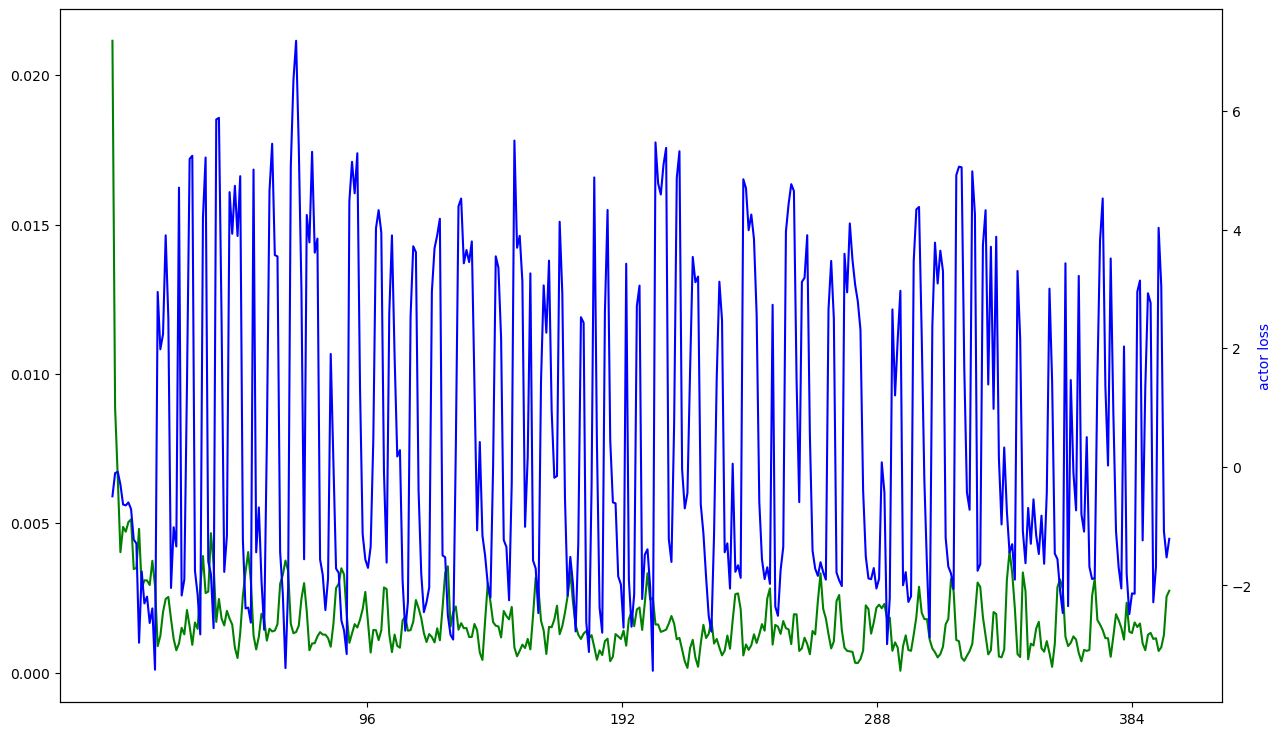

In [2]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(1, 1, figsize=(15, 9))
x = np.linspace(0, len(critic_loss), len(critic_loss))
len(x)

y_critic = critic_loss
ax1.set_xticks([i*96 for i in range(1,26, 1)])
ax1.plot(x, y_critic, label = 'critic loss over epochs', color = 'green')

ax2 = ax1.twinx()
y_actor = actor_loss
ax2.set_ylabel('actor loss', color = 'blue')
ax2.plot(x, y_actor, label = 'actor loss over epochs', color = 'blue')


In [13]:
max(STATIC_BR.values())

0.0

In [14]:
N_EPOCHS = 100
recent_tenders = trained_dcmab.tender_history[-N_EPOCHS:] if len(trained_dcmab.tender_history) >= N_EPOCHS else trained_dcmab.tender_history

In [15]:
for item in recent_tenders:
    if item['winner'] == 434:
        print(item['winner'], item['winning_bid'])
        break

434 123.93668442964554


In [ ]:
recent_tenders

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, interpolate
import os

def plot_combined_cdf_distributions(dcmab_system):
    output_dir = "agent_distributions"
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    if not dcmab_system.tender_history:
        return
    
    N_EPOCHS = 100
    recent_tenders = dcmab_system.tender_history[-N_EPOCHS:] if len(dcmab_system.tender_history) >= N_EPOCHS else dcmab_system.tender_history
    
    if len(recent_tenders) == 0:
        return
    
    MARL_profit = []
    static_profit = []
    for item in recent_tenders:
        if item['winner']== 318:
             MARL_profit.append(item['winning_bid'])
        else:
            static_profit.append(item['winning_bid'])
    MARL_avg_profit = np.sum(MARL_profit)/len(recent_tenders)
    static_avg_profit = np.sum(static_profit)/len(recent_tenders)
    
    sorted_agents_by_br = sorted(AGENT_IDS, key=lambda x: STATIC_BR[x], reverse=True)
    agent_i_id = sorted_agents_by_br[0]
    agent_j_id = sorted_agents_by_br[1]
    
    br_i = STATIC_BR[agent_i_id]
    br_j = STATIC_BR[agent_j_id]
    U = U_GLOBAL

    V = 1.0 - (br_i + br_j)
    P_lower = (br_i * U) / (br_i + V)
    
    agent_bids = {}
    agent_types_history = {agent_id: [] for agent_id in dcmab_system.agents.keys()}
    
    for agent_id, agent in dcmab_system.agents.items():
        if agent_id == agent_i_id:
            agent_type = 'i'
            current_br = br_i
            opponent_br = br_j
        else:
            agent_type = 'j'
            current_br = br_j
            opponent_br = br_i
        
        state = agent.get_state(current_br, opponent_br, P_lower, U)
        print(f'list of parameters is {state, P_lower, U, N_EPOCHS}')
        sampled_bids = agent.sample_policy_bids(state, P_lower, U, N_EPOCHS)
        agent_bids[agent_id] = sampled_bids
        
        for tender in recent_tenders:
            is_agent_i = False
            if tender['courier1_id'] == agent_id:
                is_agent_i = (tender['br_i'] == br_i)
            elif tender['courier2_id'] == agent_id:
                is_agent_i = (tender['br_i'] == br_i)
            agent_types_history[agent_id].append('i' if is_agent_i else 'j')
    
    class TheoreticalDist:
        def __init__(self, br_i, br_j, U):
            V = 1.0 - (br_i + br_j)
            self.P_lower = (br_i * U) / (br_i + V)
    
    avg_theoretical_dist = TheoreticalDist(br_i, br_j, U)
    
    def theoretical_cdf(P, br_i, br_j, U, agent_type):
        V = 1.0 - (br_i + br_j)
        P_lower = (br_i * U) / (br_i + V)
        
        if P < P_lower:
            return 0.0
        elif P > U:
            return 1.0
        else:
            if agent_type == 'i':
                return 1.0
            else:
                return 1.0
    
    fig, ax = plt.subplots(1, 1, figsize=(15, 9))
    
    colors = ['blue', 'red']
    
    last_tender = recent_tenders[-1] if recent_tenders else None
    
    if last_tender:
        P_winner = last_tender['winning_bid']
        W_c = U - P_winner
        W_w = P_winner - P_lower
    
    for idx, (agent_id, bids) in enumerate(agent_bids.items()):
        if len(bids) < 5:
            continue
        
        type_history = agent_types_history[agent_id]
        if not type_history:
            continue
        
        agent_type = 'i' if agent_id == agent_i_id else 'j'
        
        sorted_empirical = np.sort(bids)
        empirical_cdf = np.arange(1, len(sorted_empirical) + 1) / len(sorted_empirical)
        
        x_emp_extended = np.concatenate([[P_lower], sorted_empirical, [U, U * 1.02]])
        y_emp_extended = np.concatenate([[0], empirical_cdf, [1, 1]])
        
        f_emp = interpolate.interp1d(x_emp_extended, y_emp_extended, 
                                     kind='linear', bounds_error=False,
                                     fill_value=(0, 1))
        
        cdf_x_range = np.linspace(0, U, 500)
        empirical_cdf_interp = f_emp(cdf_x_range)
        
        sorted_empirical_with_U = np.concatenate([[P_lower], sorted_empirical, [U]])
        empirical_cdf_with_U = np.concatenate([[0], empirical_cdf, [1]])
        
        theo_x_range = np.linspace(P_lower, U, 500)
        theoretical_cdf_smooth = [theoretical_cdf(x, br_i, br_j, U, agent_type) 
                                 for x in theo_x_range]
        
        ax.step(sorted_empirical_with_U, empirical_cdf_with_U, where='post', 
                color=colors[idx], linewidth=3.5,
                label=f'Agent {agent_id} ({agent_type.upper()})\nEmpirical CDF')
        
        ax.plot(theo_x_range, theoretical_cdf_smooth, '--', 
                color=colors[idx], linewidth=3, alpha=0.9,
                label=f'Agent {agent_id} ({agent_type.upper()})\nTheoretical CDF')
        
        f_theo = interpolate.interp1d(theo_x_range, theoretical_cdf_smooth, 
                                     kind='linear', bounds_error=False,
                                     fill_value=(0, 1))
        theoretical_on_emp_range = f_theo(cdf_x_range)
        
        where_emp_gt_theo = empirical_cdf_interp > theoretical_on_emp_range
        
        if np.any(where_emp_gt_theo):
            ax.fill_between(cdf_x_range, theoretical_on_emp_range, empirical_cdf_interp,
                          where=where_emp_gt_theo,
                          color=colors[idx], alpha=0.15)
        
        where_theo_gt_emp = theoretical_on_emp_range > empirical_cdf_interp
        if np.any(where_theo_gt_emp):
            ax.fill_between(cdf_x_range, empirical_cdf_interp, theoretical_on_emp_range,
                          where=where_theo_gt_emp,
                          color=colors[idx], alpha=0.15)
    
    ax.axvline(x=P_lower, color='orange', linestyle='--',
               linewidth=3.5, alpha=0.9, label=f'P$^{{lower}}$ = {P_lower:.3f}')
    ax.axvline(x=U, color='green', linestyle='--',
               linewidth=3.5, alpha=0.9, label=f'U = {U:.3f}')
    
    ax.set_xlabel('Bid Value', fontsize=26, fontweight='bold')
    ax.set_ylabel('CDF', fontsize=26, fontweight='bold')
    
    ax.set_xticks([100, 400, 700, 1000])
    ax.tick_params(axis='both', which='major', labelsize=24)
    ax.tick_params(axis='both', which='minor', labelsize=24)
    
    ax.set_xlim(300, 1000)
    ax.set_ylim(-0.02, 1.02)
    
    ax.set_title('Empirical vs Theoretical CDF\n' +
                f'Agent i (BR={br_i}) vs Agent j (BR={br_j})', 
                 fontsize=26, fontweight='bold', pad=30)
    
    ax.grid(True, alpha=0.9, linestyle='--')
    
    info_text = f"Tender results\n"
    info_text += f"Last iteration: n = 2000\n"
    info_text += f"Citizen's welfare: {W_c:.3f}\n"
    info_text += f"Winner's profit: {W_w:.3f}\n"
    info_text += f"BR_i = {br_i}, BR_j = {br_j}\n"
    info_text += f"P_lower = {P_lower:.3f}, U = {U}\n"
    info_text += f"avg. MARL agent profit = {MARL_avg_profit}\n"
    info_text += f"avg. MARL agent profit = {static_avg_profit}"
    
    props = dict(boxstyle='round', facecolor='lightyellow', alpha=0.95,
                edgecolor='goldenrod', linewidth=3)
    
    from matplotlib.lines import Line2D
    
    legend_elements = []
    
    for idx, agent_id in enumerate(agent_bids.keys()):
        if idx < 2:
            agent_type = 'i' if agent_id == agent_i_id else 'j'
            legend_elements.append(Line2D([0], [0], color=colors[idx], lw=3.5, 
                                          label=f'Agent {agent_id} ({agent_type.upper()})\nEmpirical CDF'))
            legend_elements.append(Line2D([0], [0], color=colors[idx], lw=3, linestyle='--', 
                                          label=f'Agent {agent_id} ({agent_type.upper()})\nTheoretical CDF'))
    
    legend_agents = ax.legend(handles=legend_elements[:4], loc='lower center',
                            bbox_to_anchor=(0.5, -0.65), ncol=4, fontsize=18,
                            framealpha=0.95, frameon=True, edgecolor='black',
                            title="Theoretical and Experimental CDF of Agents",
                            title_fontsize=20)
    ax.add_artist(legend_agents)

    u_line = Line2D([0], [0], color='green', lw=3.5, linestyle='--', 
                    label=f'U = {U:.3f}')
    
    legend_citizen = ax.legend(handles=[u_line], loc='lower center',
                             bbox_to_anchor=(0.18, -1.0), ncol=1, fontsize=18,
                             framealpha=0.95, frameon=True, edgecolor='black',
                             title="Citizen's preferences",
                             title_fontsize=20)
    ax.add_artist(legend_citizen)

    time_line = Line2D([0], [0], color='orange', lw=3.5, linestyle='--', 
                       label=f'P$^{{lower}}$ = {P_lower:.3f}')
    
    legend_time = ax.legend(handles=[time_line], loc='lower left',
                         bbox_to_anchor=(0.32, -1.1), ncol=1, fontsize=18,
                         framealpha=0.95, frameon=True, edgecolor='black',
                         title=f"Time Window\n$f_{{\\, N}}^{{\\, U}}$ = 291.8",
                         title_fontsize=20)

    ax.text(0.8, -0.7, info_text, transform=ax.transAxes, fontsize=18,
            verticalalignment='top', horizontalalignment='center',
            bbox=props)
    
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.5)
    
    filename = os.path.join(output_dir, 'combined_cdf_distributions.png')
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.close(fig)
    
    print(f"Saved to {filename}")
    return filename

plot_combined_cdf_distributions(trained_dcmab)

list of parameters is (tensor([1.0000, 0.5000, 0.5000, 0.0000]), 900.0, 900, 100)
list of parameters is (tensor([1.0000, 0.5000, 0.5000, 0.0000]), 900.0, 900, 100)
Saved to agent_distributions\combined_cdf_distributions.png


'agent_distributions\\combined_cdf_distributions.png'

In [ ]:
import pickle
import pandas as pd
import numpy as np
from itertools import product, combinations_with_replacement
import logging
from datetime import datetime
import random

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

# =============================================================================
# LAYER 1: Parameter Space Generators
# =============================================================================

def generate_br_pairs(br_min=0.05, br_max=0.5, br_step=0.05):
    """
    Generate valid (br_i, br_j) pairs where br_i >= br_j.
    Returns list of tuples [(br_i, br_j), ...]
    """
    br_values = np.arange(br_min, br_max + br_step/2, br_step)
    pairs = []
    for br_i in br_values:
        for br_j in br_values:
            if br_i >= br_j:  # Ensure i is the stronger agent
                pairs.append((round(br_i, 2), round(br_j, 2)))
    return pairs

def generate_u_values(u_min=100, u_max=1500, n_samples=8):
    """Generate U values linearly spaced."""
    return np.linspace(u_min, u_max, n_samples)

def sample_configs(full_params, sample_fraction=0.01, random_seed=42):
    """
    Stratified sampling of configuration space for tractability.
    """
    random.seed(random_seed)
    
    # Generate full Cartesian product
    all_configs = [dict(zip(full_params.keys(), values)) 
                   for values in product(*full_params.values())]
    
    # FIX: stratification_key must unpack br_pair tuple
    stratification_key = lambda c: (c['br_pair'][0], c['br_pair'][1], int(c['U'] // 100))
    stratified = {}
    
    for config in all_configs:
        key = stratification_key(config)
        if key not in stratified:
            stratified[key] = []
        stratified[key].append(config)
    
    # Sample from each stratum
    sampled = []
    samples_per_stratum = max(1, int(sample_fraction * len(all_configs) / len(stratified)))
    
    for stratum_configs in stratified.values():
        n_sample = min(samples_per_stratum, len(stratum_configs))
        sampled.extend(random.sample(stratum_configs, n_sample))
    
    logger.info(f"Sampled {len(sampled)} configs from {len(all_configs)} total ({100*len(sampled)/len(all_configs):.2f}%)")
    return sampled


# =============================================================================
# LAYER 2: Extended Single Configuration Runner
# =============================================================================

def run_single_configuration_extended(num_epochs: int, tenders_per_epoch: int, 
                                      patience_limit: int, br_i: float, br_j: float, U: float):
    """
    Run training with specific hyperparameters AND game parameters.
    """
    logger.info(f"Running: epochs={num_epochs}, tenders={tenders_per_epoch}, "
                f"patience={patience_limit}, br_i={br_i}, br_j={br_j}, U={U}")
    
    # Validate V = 1 - (br_i + br_j) > 0
    V = 1.0 - (br_i + br_j)
    if V <= 0:
        logger.warning(f"Invalid V={V:.4f} for br_i={br_i}, br_j={br_j}. Skipping.")
        return None, None
    
    # Initialize system with current game parameters
    # Note: You may need to inject these into your system classes
    global STATIC_BR, U_GLOBAL
    original_br = STATIC_BR.copy() if 'STATIC_BR' in globals() else {}
    original_U = U_GLOBAL if 'U_GLOBAL' in globals() else 600
    
    try:
        # Set global parameters for this run
        STATIC_BR = {AGENT_IDS[0]: br_i, AGENT_IDS[1]: br_j}
        U_GLOBAL = U
        
        dcmab_system = DCMABSystem()
        routing_system = RoutingSystem(dcmab_system, k=10800.0)
        routing_system.initialize_couriers(AGENT_IDS)
        
        # Pre-compute theoretical distribution
        P_lower = (br_i * U) / (br_i + V)
        TBD = TheoreticalBidDistribution(br_i, br_j, U)
        
        # Tracking variables
        best_actor_loss = float('inf')
        patience_counter = 0
        loss_history = []
        ks_history = {'epoch': [], 'agent_id': [], 'p_value': [], 'ks_stat': []}
        
        for epoch in range(num_epochs):
            stats = routing_system.simulate_working_day(
                total_seconds=43200,
                training=True,
                max_tenders=tenders_per_epoch
            )
            
            # Loss tracking & early stopping
            if hasattr(routing_system, 'avg_actor_losses') and routing_system.avg_actor_losses:
                current_loss = routing_system.avg_actor_losses[-1]
                loss_history.append(current_loss)
                
                if len(loss_history) >= patience_limit:
                    recent_window = loss_history[-patience_limit:]
                    avg_recent_loss = np.mean(recent_window)
                    
                    if np.abs(avg_recent_loss) < np.abs(best_actor_loss):
                        best_actor_loss = avg_recent_loss
                        patience_counter = 0
                    else:
                        patience_counter += int(tenders_per_epoch / 16)
                    
                    if patience_counter >= patience_limit:
                        logger.info(f"Early stopping at epoch {epoch+1}/{num_epochs}")
                        break
            
            # KS-test tracking per epoch
            agent_bids = {}
            ks_results = {}
            
            for agent_id, agent in dcmab_system.agents.items():
                agent_type = 'i' if STATIC_BR[agent_id] == br_i else 'j'
                current_br = STATIC_BR[agent_id]
                opponent_br = br_j if agent_type == 'i' else br_i
                
                state = agent.get_state(current_br, opponent_br, P_lower, U)
                sampled_bids = agent.sample_policy_bids(state, P_lower, U, n_samples=500)
                
                ks_result = TBD.ks_test_convergence(sampled_bids, agent_type)
                ks_results[agent_id] = ks_result
                
                # Record for history
                ks_history['epoch'].append(epoch)
                ks_history['agent_id'].append(agent_id)
                ks_history['p_value'].append(ks_result['p_value'])
                ks_history['ks_stat'].append(ks_result['ks_statistic'])
            
            # Check full convergence
            if all(r.get('converged', False) for r in ks_results.values()):
                logger.info(f"All agents converged at epoch {epoch+1} (br_i={br_i}, br_j={br_j}, U={U})")
                break
        
        # Final metrics
        final_critic_loss = np.mean(routing_system.total_critic_loss[-100:]) if routing_system.total_critic_loss else 0.0
        final_actor_loss = np.mean(routing_system.total_actor_loss[-100:]) if routing_system.total_actor_loss else 0.0
        
        pattern = {
            # Hyperparameters
            'epochs': num_epochs,
            'tenders': tenders_per_epoch,
            'stop_cr': patience_limit,
            # Game parameters (NEW)
            'br_i': br_i,
            'br_j': br_j,
            'U': U,
            'V': V,
            'P_lower': P_lower,
            # Results
            'critic_loss': float(final_critic_loss),
            'actor_loss': float(final_actor_loss),
            'total_epochs_run': epoch + 1,
            'final_win_rates': {aid: agent.win_rate for aid, agent in dcmab_system.agents.items()},
            'final_KS_pvalues': {aid: ks_results[aid]['p_value'] for aid in ks_results},
            'all_converged': all(r.get('converged', False) for r in ks_results.values())
        }
        
        logger.info(f"✓ Completed: br=({br_i},{br_j}), U={U}, loss=({final_critic_loss:.4f},{final_actor_loss:.4f})")
        return pattern, ks_history
        
    except Exception as e:
        logger.error(f"✗ Error in config (br_i={br_i}, br_j={br_j}, U={U}): {e}")
        return {
            'epochs': num_epochs, 'tenders': tenders_per_epoch, 'stop_cr': patience_limit,
            'br_i': br_i, 'br_j': br_j, 'U': U,
            'critic_loss': float('nan'), 'actor_loss': float('nan'),
            'error': str(e)
        }, None
    finally:
        # Restore original globals
        if 'original_br' in locals():
            STATIC_BR = original_br
        if 'original_U' in locals():
            U_GLOBAL = original_U


# =============================================================================
# LAYER 3: Extended Hyperparameter Search with Sampling
# =============================================================================

def run_extended_hyperparameter_search(
    epoch_range=(100, 400, 100),
    tender_range=(64, 192, 64),
    patience_range=(50, 150, 50),
    br_range=(0.05, 0.5, 0.05),
    u_range=(100, 1500, 8),
    sample_fraction=0.1,  # Sample 2% of full space by default
    save_path='extended_search_results.pkl',
    save_interval=10
):
    """
    Run extended hyperparameter search with BR/U exploration and stratified sampling.
    """
    # Generate parameter spaces
    epochs_list = list(range(epoch_range[0], epoch_range[1] + 1, epoch_range[2]))
    tenders_list = list(range(tender_range[0], tender_range[1] + 1, tender_range[2]))
    patience_list = list(range(patience_range[0], patience_range[1] + 1, patience_range[2]))
    br_pairs = generate_br_pairs(*br_range)
    u_values = generate_u_values(*u_range)
    
    # Full parameter dict for sampling
    full_params = {
        'epochs': epochs_list,
        'tenders': tenders_list,
        'stop_cr': patience_list,
        'br_pair': br_pairs,
        'U': u_values.tolist()
    }
    
    total_full = len(epochs_list) * len(tenders_list) * len(patience_list) * len(br_pairs) * len(u_values)
    logger.info(f"Full configuration space: {total_full:,} configs")
    
    # Sample configurations
    sampled_configs = sample_configs(full_params, sample_fraction=sample_fraction)
    total_sampled = len(sampled_configs)
    logger.info(f"Sampled configurations: {total_sampled:,} ({100*sample_fraction:.1f}%)")
    
    all_patterns = []
    all_ks_histories = []
    start_time = datetime.now()
    
    for idx, config in enumerate(sampled_configs):
        logger.info(f"\n{'='*80}")
        logger.info(f"Config {idx+1}/{total_sampled}")
        logger.info(f"{'='*80}")
        
        # FIX: Unpack br_pair tuple
        br_i, br_j = config['br_pair']
        
        pattern, ks_hist = run_single_configuration_extended(
            num_epochs=config['epochs'],
            tenders_per_epoch=config['tenders'],
            patience_limit=config['stop_cr'],
            br_i=br_i,      # ← unpacked from br_pair
            br_j=br_j,      # ← unpacked from br_pair
            U=config['U']
        )
        
        if pattern is not None:
            all_patterns.append(pattern)
            if ks_hist:
                all_ks_histories.append(ks_hist)
        
        # Checkpointing
        if (idx + 1) % save_interval == 0:
            with open(save_path, 'wb') as f:
                pickle.dump({'patterns': all_patterns, 'ks_histories': all_ks_histories}, f)
            logger.info(f"✓ Checkpoint saved: {len(all_patterns)} results")
        
        # Progress timing
        elapsed = datetime.now() - start_time
        avg_time = elapsed / (idx + 1)
        remaining = avg_time * (total_sampled - idx - 1)
        logger.info(f"⏱️  Elapsed: {elapsed}, Est. remaining: {remaining}")
    
    # Final save
    with open(save_path, 'wb') as f:
        pickle.dump({'patterns': all_patterns, 'ks_histories': all_ks_histories}, f)
    
    logger.info(f"\n{'='*80}")
    logger.info(f"✅ Search completed! Results: {len(all_patterns)}/{total_sampled} successful")
    logger.info(f"📁 Saved to: {save_path}")
    logger.info(f"{'='*80}")
    
    return all_patterns, all_ks_histories


# =============================================================================
# Extended Analysis Functions
# =============================================================================

def analyze_extended_results(patterns):
    """
    Analyze results with BR/U dimensions.
    """
    df = pd.DataFrame(patterns)
    
    print("\n" + "="*80)
    print("EXTENDED HYPERPARAMETER SEARCH RESULTS")
    print("="*80)
    
    valid_df = df.dropna(subset=['critic_loss', 'actor_loss'])
    
    if len(valid_df) == 0:
        print("⚠️  No valid results to analyze")
        return df
    
    # Summary by game parameters
    print(f"\n📊 Coverage: {valid_df['br_i'].nunique()} br_i values × "
          f"{valid_df['br_j'].nunique()} br_j values × {valid_df['U'].nunique()} U values")
    
    # Best by convergence rate
    print("\n🏆 Top configurations by CONVERGENCE RATE:")
    conv_rates = valid_df.groupby(['br_i', 'br_j', 'U'])['all_converged'].mean().reset_index()
    top_conv = conv_rates.nlargest(5, 'all_converged')
    print(top_conv.to_string(index=False))
    
    # Loss vs. game difficulty
    print("\n📈 Loss vs. Game Difficulty (V = 1 - br_i - br_j):")
    valid_df['V'] = 1 - valid_df['br_i'] - valid_df['br_j']
    difficulty_bins = pd.cut(valid_df['V'], bins=5, labels=['Very Hard', 'Hard', 'Medium', 'Easy', 'Very Easy'])
    loss_by_diff = valid_df.groupby(difficulty_bins)[['critic_loss', 'actor_loss']].mean()
    print(loss_by_diff.round(4))
    
    # U sensitivity
    print("\n🔍 Actor Loss vs. U (marginal effect):")
    u_groups = pd.cut(valid_df['U'], bins=10)
    u_sensitivity = valid_df.groupby(u_groups)['actor_loss'].agg(['mean', 'std', 'count'])
    print(u_sensitivity.round(4))
    
    return df


def plot_br_u_heatmap(patterns, metric='actor_loss'):
    """
    Create heatmap of metric vs. (br_i, br_j) for fixed U slices.
    Requires matplotlib/seaborn.
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    df = pd.DataFrame(patterns)
    valid_df = df.dropna(subset=[metric])
    
    # Pick representative U values
    u_samples = valid_df['U'].quantile([0.25, 0.5, 0.75]).tolist()
    
    fig, axes = plt.subplots(1, len(u_samples), figsize=(18, 5))
    if len(u_samples) == 1:
        axes = [axes]
    
    for ax, u_val in zip(axes, u_samples):
        subset = valid_df[np.isclose(valid_df['U'], u_val, atol=10)]
        if len(subset) == 0:
            ax.text(0.5, 0.5, f'No data\nU≈{u_val:.0f}', ha='center', va='center', transform=ax.transAxes)
            continue
        
        pivot = subset.pivot_table(values=metric, index='br_i', columns='br_j', aggfunc='mean')
        sns.heatmap(pivot, ax=ax, cmap='viridis', annot=True, fmt='.3f')
        ax.set_title(f'{metric} at U ≈ {u_val:.0f}')
        ax.set_xlabel('br_j (weaker agent)')
        ax.set_ylabel('br_i (stronger agent)')
    
    plt.tight_layout()
    plt.savefig('br_u_heatmap.png', dpi=150, bbox_inches='tight')
    logger.info("📊 Heatmap saved to br_u_heatmap.png")
    return fig


# =============================================================================
# Example Usage
# =============================================================================

if __name__ == "__main__":
    # Run extended search with 2% sampling (~8,000 configs instead of 400,000)
    patterns, ks_histories = run_extended_hyperparameter_search(
        epoch_range=(100, 300, 100),
        tender_range=(64, 128, 64),
        patience_range=(50, 100, 50),
        br_range=(0.05, 0.5, 0.05),
        u_range=(100, 1500, 200),
        sample_fraction=0.2,  # Critical: adjust for your compute budget
        save_path='extended_search_results.pkl',
        save_interval=20
    )
    
    # Analyze
    df = analyze_extended_results(patterns)
    
    # Optional: Visualize
    # plot_br_u_heatmap(patterns, metric='actor_loss')
    
    # Save as CSV for external analysis
    pd.DataFrame(patterns).to_csv('extended_search_results.csv', index=False)
    logger.info("📄 Results exported to CSV")